# EDA — Olist Brazilian E-commerce

Exploration du socle transactionnel : volumétrie, statuts de commande, avis, sparsité client (fondement des choix faits dans `analytics/rfm_olist.py` et `analytics/market_basket_olist.py` — voir `docs/limitations-methodologiques.md`).

In [1]:
import os
from pathlib import Path
from dotenv import load_dotenv
from sqlalchemy import create_engine
import pandas as pd
import matplotlib.pyplot as plt

load_dotenv()  # cherche .env dans le répertoire courant puis ses parents
engine = create_engine(os.environ["DATABASE_URL"])
plt.rcParams["figure.figsize"] = (9, 4)

## Volumétrie générale

In [2]:
volumetrie = pd.read_sql("""
    SELECT 'clients (customer_unique_id)' AS entite, COUNT(DISTINCT customer_unique_id) AS n FROM olist.customers
    UNION ALL SELECT 'commandes', COUNT(*) FROM olist.orders
    UNION ALL SELECT 'produits', COUNT(*) FROM olist.products
    UNION ALL SELECT 'vendeurs', COUNT(*) FROM olist.sellers
    UNION ALL SELECT 'avis', COUNT(*) FROM olist.order_reviews
""", engine)
volumetrie

,entite,n
0,vendeurs,3095
1,produits,32951
2,avis,99224
3,clients (customer_unique_id),96096
4,commandes,99441


## Répartition des statuts de commande

Justifie le filtre `order_status = 'delivered'` utilisé dans les modules RFM et market basket : une commande annulée ou jamais livrée ne représente pas un comportement d'achat réel.

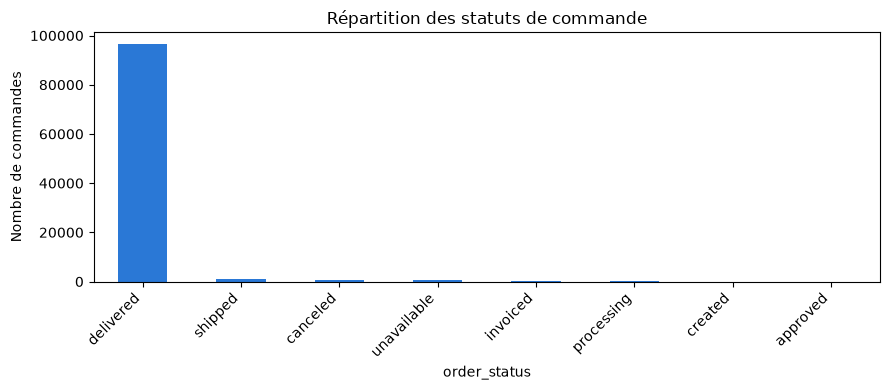

,order_status,n
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


In [3]:
statuts = pd.read_sql(
    "SELECT order_status, COUNT(*) AS n FROM olist.orders GROUP BY order_status ORDER BY n DESC", engine)
ax = statuts.set_index("order_status")["n"].plot.bar(color="#2a78d6")
ax.set_ylabel("Nombre de commandes")
ax.set_title("Répartition des statuts de commande")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
statuts

## Distribution des notes d'avis

Sert de base au label faible ('weak supervision') utilisé dans `analytics/sentiment_olist.py` (1-2★→négatif, 3★→neutre, 4-5★→positif).

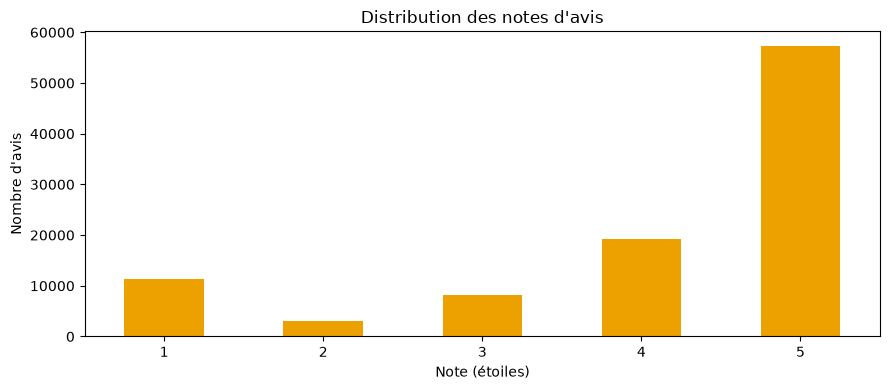

In [4]:
notes = pd.read_sql(
    "SELECT review_score, COUNT(*) AS n FROM olist.order_reviews GROUP BY review_score ORDER BY review_score", engine)
ax = notes.set_index("review_score")["n"].plot.bar(color="#eda100")
ax.set_xlabel("Note (étoiles)")
ax.set_ylabel("Nombre d'avis")
ax.set_title("Distribution des notes d'avis")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Sparsité client : nombre de commandes par client

Le résultat central qui a guidé la conception du module RFM : la quasi-totalité des clients n'a commandé qu'une seule fois, ce qui rend la composante Fréquence du RFM peu discriminante (voir `docs/limitations-methodologiques.md`).

97.0% des clients n'ont commandé qu'une seule fois


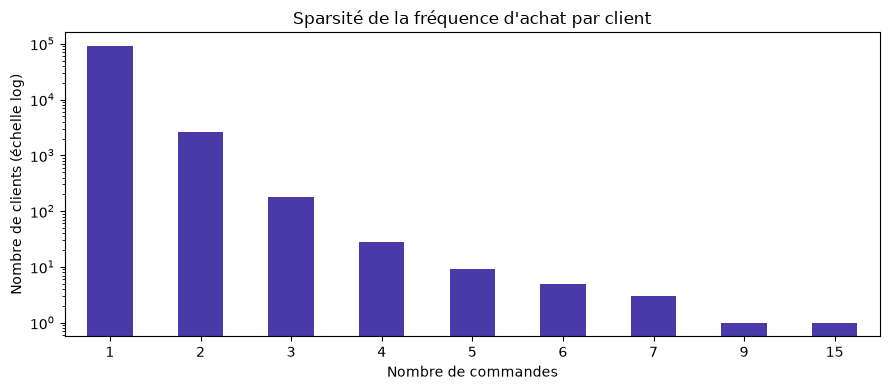

In [5]:
commandes_par_client = pd.read_sql("""
    SELECT c.customer_unique_id, COUNT(DISTINCT o.order_id) AS nb_commandes
    FROM olist.orders o JOIN olist.customers c ON c.customer_id = o.customer_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_unique_id
""", engine)

repartition = commandes_par_client["nb_commandes"].value_counts().sort_index()
pct_mono_achat = repartition.loc[1] / repartition.sum() * 100
print(f"{pct_mono_achat:.1f}% des clients n'ont commandé qu'une seule fois")

ax = repartition.head(10).plot.bar(color="#4a3aa7", logy=True)
ax.set_xlabel("Nombre de commandes")
ax.set_ylabel("Nombre de clients (échelle log)")
ax.set_title("Sparsité de la fréquence d'achat par client")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Répartition géographique (top 10 états)

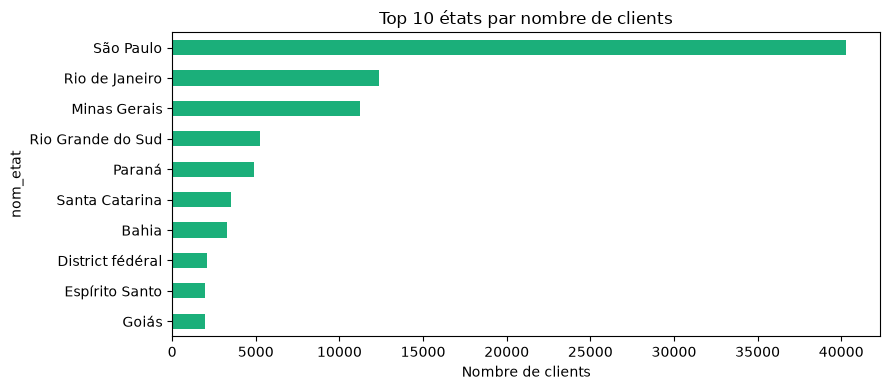

In [6]:
geo = pd.read_sql("""
    SELECT customer_state, COUNT(DISTINCT customer_unique_id) AS n
    FROM olist.customers WHERE customer_state IS NOT NULL
    GROUP BY customer_state ORDER BY n DESC LIMIT 10
""", engine)

STATE_NAMES = {
    "AC": "Acre", "AL": "Alagoas", "AP": "Amapá", "AM": "Amazonas", "BA": "Bahia",
    "CE": "Ceará", "DF": "District fédéral", "ES": "Espírito Santo", "GO": "Goiás",
    "MA": "Maranhão", "MT": "Mato Grosso", "MS": "Mato Grosso do Sud", "MG": "Minas Gerais",
    "PA": "Pará", "PB": "Paraíba", "PR": "Paraná", "PE": "Pernambouc", "PI": "Piauí",
    "RJ": "Rio de Janeiro", "RN": "Rio Grande do Norte", "RS": "Rio Grande do Sud",
    "RO": "Rondônia", "RR": "Roraima", "SC": "Santa Catarina", "SP": "São Paulo",
    "SE": "Sergipe", "TO": "Tocantins",
}
geo["nom_etat"] = geo["customer_state"].map(STATE_NAMES).fillna(geo["customer_state"])

ax = geo.set_index("nom_etat")["n"].plot.barh(color="#1baf7a")
ax.invert_yaxis()
ax.set_xlabel("Nombre de clients")
ax.set_title("Top 10 états par nombre de clients")
plt.tight_layout()
plt.show()

## Top 10 catégories de produits (par nombre d'articles vendus)

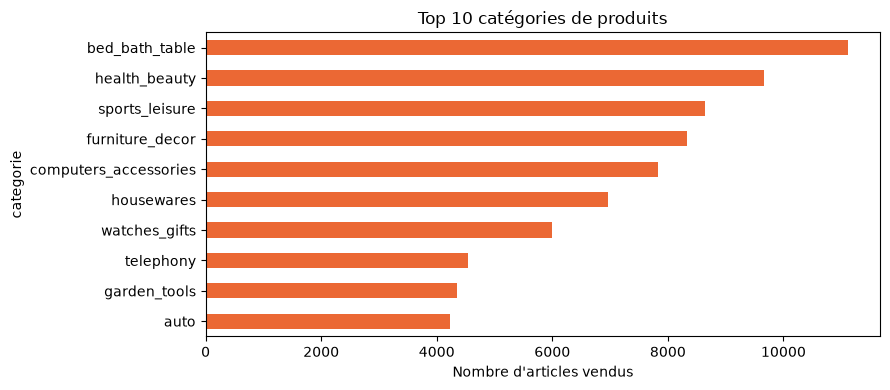

In [7]:
categories = pd.read_sql("""
    SELECT COALESCE(ct.product_category_name_english, p.product_category_name) AS categorie,
           COUNT(*) AS n
    FROM olist.order_items oi
    JOIN olist.products p ON p.product_id = oi.product_id
    LEFT JOIN olist.category_translation ct ON ct.product_category_name = p.product_category_name
    GROUP BY categorie ORDER BY n DESC LIMIT 10
""", engine)
ax = categories.set_index("categorie")["n"].plot.barh(color="#eb6834")
ax.invert_yaxis()
ax.set_xlabel("Nombre d'articles vendus")
ax.set_title("Top 10 catégories de produits")
plt.tight_layout()
plt.show()